## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sam Leal

**Date:** 10/20/2026

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598)]
unique tokens: 48691


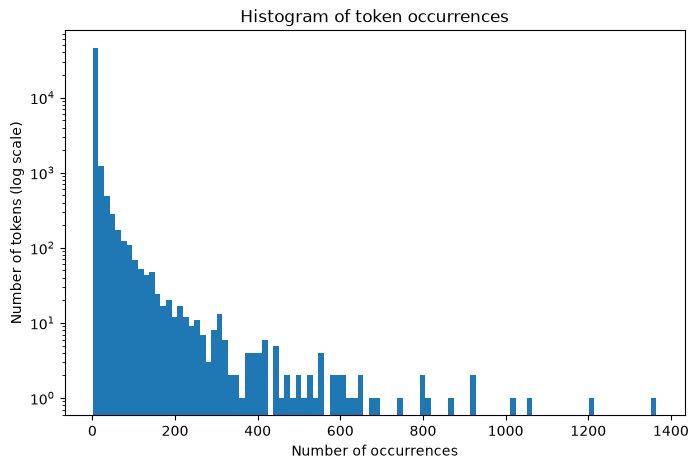

In [ ]:
# Your Phase 1 solution to the problem goes here.
# Q1
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(token_freq[:20])   # top 20 tokens
print("unique tokens:", len(token_freq))

counts = np.array([count for token, count in token_freq])

plt.figure(figsize=(8, 5))
plt.hist(counts, bins=100)
plt.yscale("log")
plt.xlabel("Number of occurrences")
plt.ylabel("Number of tokens (log scale)")
plt.title("Histogram of token occurrences")
plt.show()

# The distribution of token occurrences is extremely right-skewed. 
# Even with the y-axis on a log scale, the first bar, covering tokens that appear fewer than about 15 times, stands far above the rest at over 40,000 tokens. 
# The next bar drops to around 1,000, and the counts keep falling steeply from there. 
# Past about 400 occurrences, the bars become sparse and scattered, and most bins hold only one or two tokens. 
# The most common tokens appear around 1,200–1,400 times. 
# So most words are rare, and only a small handful show up very often. 
# This also explains why the cleaned dataset in Q2 keeps only tokens that appear in at least 15 emails.

In [6]:
#Q2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')
print(df.shape)
df.head()

y = df["Email Type"]
X = df.drop(columns=["Email Type"])
# If df.head() showed an index column like "Unnamed: 0", drop it too:
# X = X.drop(columns=["Unnamed: 0"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=125
)
print(X_train.shape, X_test.shape)

reg = LinearRegression().fit(X_train, y_train)

print("R-squared (train):", round(reg.score(X_train, y_train), 4))
print("R-squared (test): ", round(reg.score(X_test, y_test), 4))

coefs = pd.Series(reg.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
top.head(20)

# The R^2 is 0.766 on the training set and 0.670 on the test set. 
# The model explains a good amount of the variation in whether an email is phishing.
# The drop of about 0.10 on the test set suggests some overfitting, which makes sense with 2,711 features to work with.

# The tokens with the largest coefficients in absolute value are background-image: (−1.20), localized (0.82), aging (0.74), thermal (0.59), helvetica, (0.59), intervention (−0.58), erectile (0.58), and burning (−0.57).
# Positive coefficients push predictions toward phishing, and negative ones push them toward legitimate. 
# Some of these make intuitive sense: “erectile,” “xanaax,” and “girlfriend” are typical spam words, while “cnet” and “zdnet” point to legitimate tech newsletters. Many of the top tokens, though, are HTML/CSS fragments like “background-image:,” “helvetica,” and “arial,” whose signs don’t follow a consistent pattern. 
# These tokens probably show up together in the same emails. 
# That kind of correlation can produce large, offsetting coefficients that are hard to interpret on their own.

(18634, 2712)
(14907, 2711) (3727, 2711)
R-squared (train): 0.766
R-squared (test):  0.6702


background-image:   -1.201203
localized            0.815112
aging                0.735023
thermal              0.590412
helvetica,           0.587472
intervention        -0.580474
erectile             0.575784
burning             -0.569225
form.                0.560255
april's             -0.525984
cnet                -0.495563
xanaax               0.490234
zdnet               -0.487835
arial,              -0.483577
rcs                  0.464646
transcript           0.463811
quality,             0.451875
sais                 0.441776
girlfriend           0.410499
ï¿½ï¿½               0.408999
dtype: float64

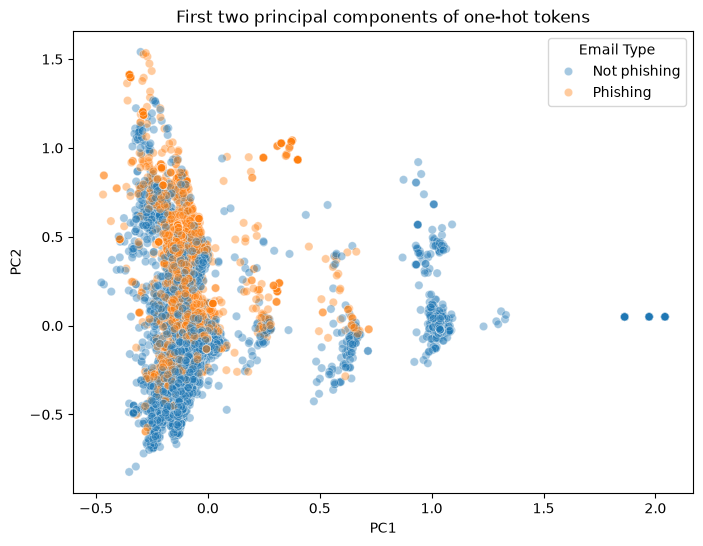

Explained variance ratio: [0.0111 0.0086]


In [13]:
# Q3
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)
pcs = pca2.fit_transform(X)

pc_df = pd.DataFrame({
    "PC1": pcs[:, 0],
    "PC2": pcs[:, 1],
    "Email Type": y.map({1: "Phishing", 0: "Not phishing"}),
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pc_df, x="PC1", y="PC2", hue="Email Type", alpha=0.4)
plt.title("First two principal components of one-hot tokens")
plt.show()

print("Explained variance ratio:", pca2.explained_variance_ratio_.round(4))

# Most emails fall into one dense cluster at the left of the plot (PC1 between about −0.4 and 0.1), where the phishing and non-phishing emails overlap heavily. 
# Within that cluster there’s a loose split: phishing emails tend to sit higher on PC2, and legitimate emails gather toward the bottom. 
# Farther right, there are a few distinct vertical bands around PC1 ≈ 0.6 and PC1 ≈ 1.0, plus a handful of points near 2.0. 
# These are almost entirely non-phishing. 
# They may be groups of similar, templated emails like newsletters that share many of the same tokens. 
# There’s also a small, tight group of phishing emails around PC1 ≈ 0.3, PC2 ≈ 1.0. 
# Overall, the first two components show some meaningful structure, especially high PC1 pointing to legitimate emails. 
# Still, the classes overlap a lot, so two components alone aren’t enough to separate phishing from non-phishing.

In [15]:
#Q4
# Fit PCA on the training data only, then apply it to the test data
pca_big = PCA(n_components=2610)
Z_train = pca_big.fit_transform(X_train)
Z_test = pca_big.transform(X_test)

reg_pca = LinearRegression().fit(Z_train, y_train)

print("R-squared (train):", round(reg_pca.score(Z_train, y_train), 4))
print("R-squared (test): ", round(reg_pca.score(Z_test, y_test), 4))

# Regressing on the first 2,610 principal components gives an R^2 of 0.765 on the training set and 0.672 on the test set. 
# That’s nearly identical to the original regression (0.766 train, 0.670 test). 
# Training R^2 dropped very slightly, and test R^2 went up very slightly, so the gap between them narrowed a little. 
# Dropping the last ~100 components barely changed the fit, which suggests those directions held very little useful information, mostly noise or redundancy among correlated tokens. 
# So we get essentially the same predictive performance with fewer, uncorrelated features, and there’s a small hint of less overfitting.

R-squared (train): 0.7651
R-squared (test):  0.6718


In [16]:
# Q5
# With around 2,700 token columns, many words tend to appear together, and many are pretty rare. 
# This makes the original regression unstable: coefficients can get really large or flip signs just to fit noise, like we saw with the HTML tokens in Q2. 
# Principal components fix this by combining the tokens into uncorrelated features, ranked by how much variation they capture. 
# Regressing on them gets rid of the multicollinearity problem. 
# We can also drop the lowest-variance components, which are mostly noise, so the model has fewer parameters to estimate. 
# As Q4 showed, we can do this without losing predictive power. 
# The tradeoff is interpretability: each component is a mix of many words, so it’s harder to say what any one coefficient means.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]